In [1]:
import numpy as np
import pandas as pd

TARGET = "pass"      # já vem como 0 (run) e 1 (pass)

df = pd.read_csv("../Data/DadosFiltradosParaImplementacao.csv")
df = df[df[TARGET].isin([0, 1])].copy()

df["season"] = df["season"].astype(str).str.extract(r"(\d{4})")[0].astype(int)

FEATURES = ["home", "ydstogo", "qtr", "down_1", "down_2", "down_3", "down_4",
            "shotgun", "nohuddle", "scorediff", "goaltogo", "yardline_100", "yardline90"]

train = df[df["season"] <= 2017]
test  = df[df["season"] == 2018]

X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print("Quantidade de amostras - Treino: {}, Teste: {}".format(len(train), len(test)))
## %de um modelo que prevê sempre 0 (run) é a média de classes, ou seja, a proporção de 1 (pass) no conjunto de dados.
print("Média de classes - Treino: {}, Teste: {}".format(y_train.mean(), y_test.mean()))

Quantidade de amostras - Treino: 289191, Teste: 29500
Média de classes - Treino: 0.5832166284566256, Teste: 0.5935932203389831


In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

clf = DecisionTreeClassifier(max_depth=5, random_state=42)

clf.fit(X_train, y_train)                 # aprende a árvore com os dados de treino
y_pred = clf.predict(X_test)              # classe prevista (0 ou 1)
y_proba = clf.predict_proba(X_test)[:, 1] # probabilidade de ser pass (classe 1)
acc = clf.score(X_test, y_test)           # atalho: acurácia média em (X_test, y_test)

In [3]:
print("Acurácia :", accuracy_score(y_test, y_pred))
print("Precision (run):", precision_score(y_test, y_pred, pos_label=0))
print("Recall    (run):", recall_score(y_test, y_pred, pos_label=0))
print("Precision (pass):", precision_score(y_test, y_pred, pos_label=1))
print("Recall    (pass):", recall_score(y_test, y_pred, pos_label=1))
print(classification_report(y_test, y_pred, target_names=["run", "pass"]))

Acurácia : 0.7157627118644068
Precision (run): 0.6724071947952545
Recall    (run): 0.5862040203519894
Precision (pass): 0.739552708945821
Recall    (pass): 0.8044657643766775
              precision    recall  f1-score   support

         run       0.67      0.59      0.63     11989
        pass       0.74      0.80      0.77     17511

    accuracy                           0.72     29500
   macro avg       0.71      0.70      0.70     29500
weighted avg       0.71      0.72      0.71     29500



In [4]:
from sklearn.model_selection import GridSearchCV, GroupKFold

param_grid = {
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_leaf": [1, 20, 50, 100],
    "criterion": ["gini", "entropy"],
}

# Cada fold mantém as jogadas de uma mesma temporada juntas.
# GroupKFold não mistura temporadas entre treino e validação do mesmo fold,
# mas não impõe uma ordem cronológica entre as temporadas.
cv = GroupKFold(n_splits=5)

gs = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
)

gs.fit(X_train, y_train, groups=train["season"])

print("Melhores parâmetros:", gs.best_params_)
print("Melhor acurácia (validação cruzada):", gs.best_score_)

# O melhor estimador já foi retreinado pelo GridSearchCV com todo o conjunto de treino.
best = gs.best_estimator_
y_pred_best = best.predict(X_test)

print("\nAcurácia do modelo original (max_depth=5):", accuracy_score(y_test, y_pred))
print("Acurácia do melhor modelo (teste 2018):", accuracy_score(y_test, y_pred_best))
print("Precision (run):", precision_score(y_test, y_pred_best, pos_label=0))
print("Recall    (run):", recall_score(y_test, y_pred_best, pos_label=0))
print(classification_report(y_test, y_pred_best, target_names=["run", "pass"]))

# Inspeciona as dez melhores combinações testadas.
res = pd.DataFrame(gs.cv_results_)
cols = [
    "param_max_depth", "param_min_samples_leaf", "param_criterion",
    "mean_test_score", "std_test_score", "rank_test_score"
]
display(res[cols].sort_values("rank_test_score").head(10))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Melhores parâmetros: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 100}
Melhor acurácia (validação cruzada): 0.723257795992945

Acurácia do modelo original (max_depth=5): 0.7157627118644068
Acurácia do melhor modelo (teste 2018): 0.7213559322033898
Precision (run): 0.6814986034864683
Recall    (run): 0.5902076903828509
              precision    recall  f1-score   support

         run       0.68      0.59      0.63     11989
        pass       0.74      0.81      0.78     17511

    accuracy                           0.72     29500
   macro avg       0.71      0.70      0.70     29500
weighted avg       0.72      0.72      0.72     29500



,param_max_depth,param_min_samples_leaf,param_criterion,mean_test_score,std_test_score,rank_test_score
15,10,100,gini,0.723258,0.003226,1
14,10,50,gini,0.723118,0.003466,2
39,10,100,entropy,0.722573,0.004211,3
13,10,20,gini,0.722479,0.003420,4
38,10,50,entropy,0.722352,0.004172,5
12,10,1,gini,0.722033,0.003449,6
19,15,100,gini,0.721878,0.002751,7
43,15,100,entropy,0.721851,0.002975,8
37,10,20,entropy,0.721735,0.004060,9
36,10,1,entropy,0.721663,0.004088,10


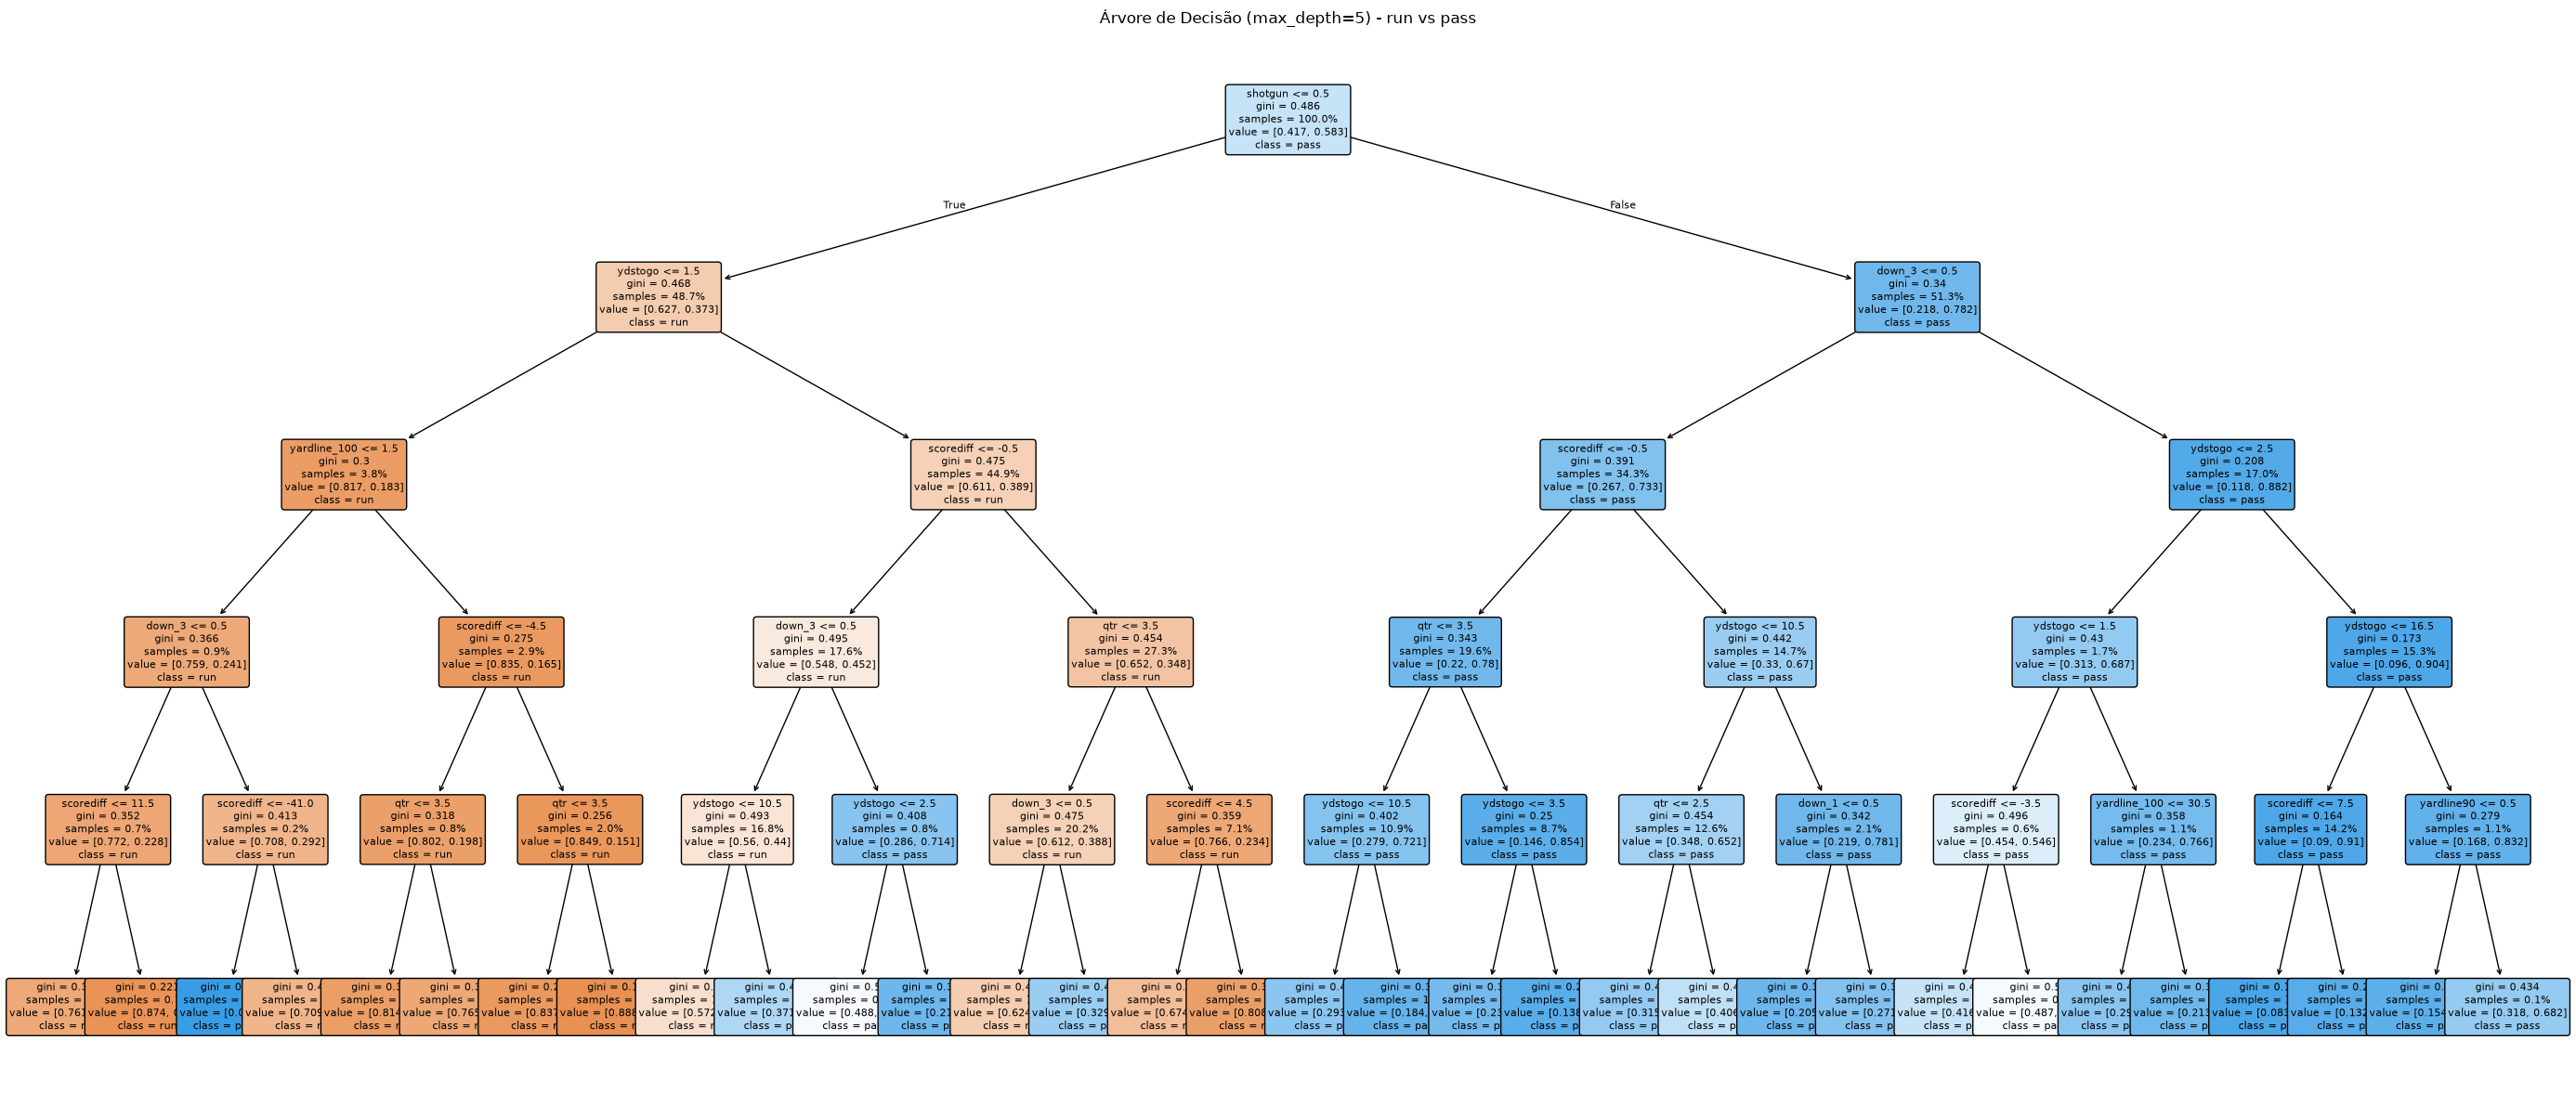

In [5]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(28, 12))
plot_tree(
    clf,
    feature_names=FEATURES,
    class_names=["run", "pass"],
    filled=True,
    rounded=True,
    fontsize=8,
    proportion=True,   # mostra a proporção de amostras em cada nó
)
plt.title("Árvore de Decisão (max_depth=5) - run vs pass")
plt.tight_layout()

# Salva em alta resolução e mostra na tela
plt.savefig("arvore_decisao.png", dpi=300, bbox_inches="tight")
plt.show()

Hiperparâmetros: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 100}
Profundidade real: 10 | Folhas: 476 | Nós totais: 951


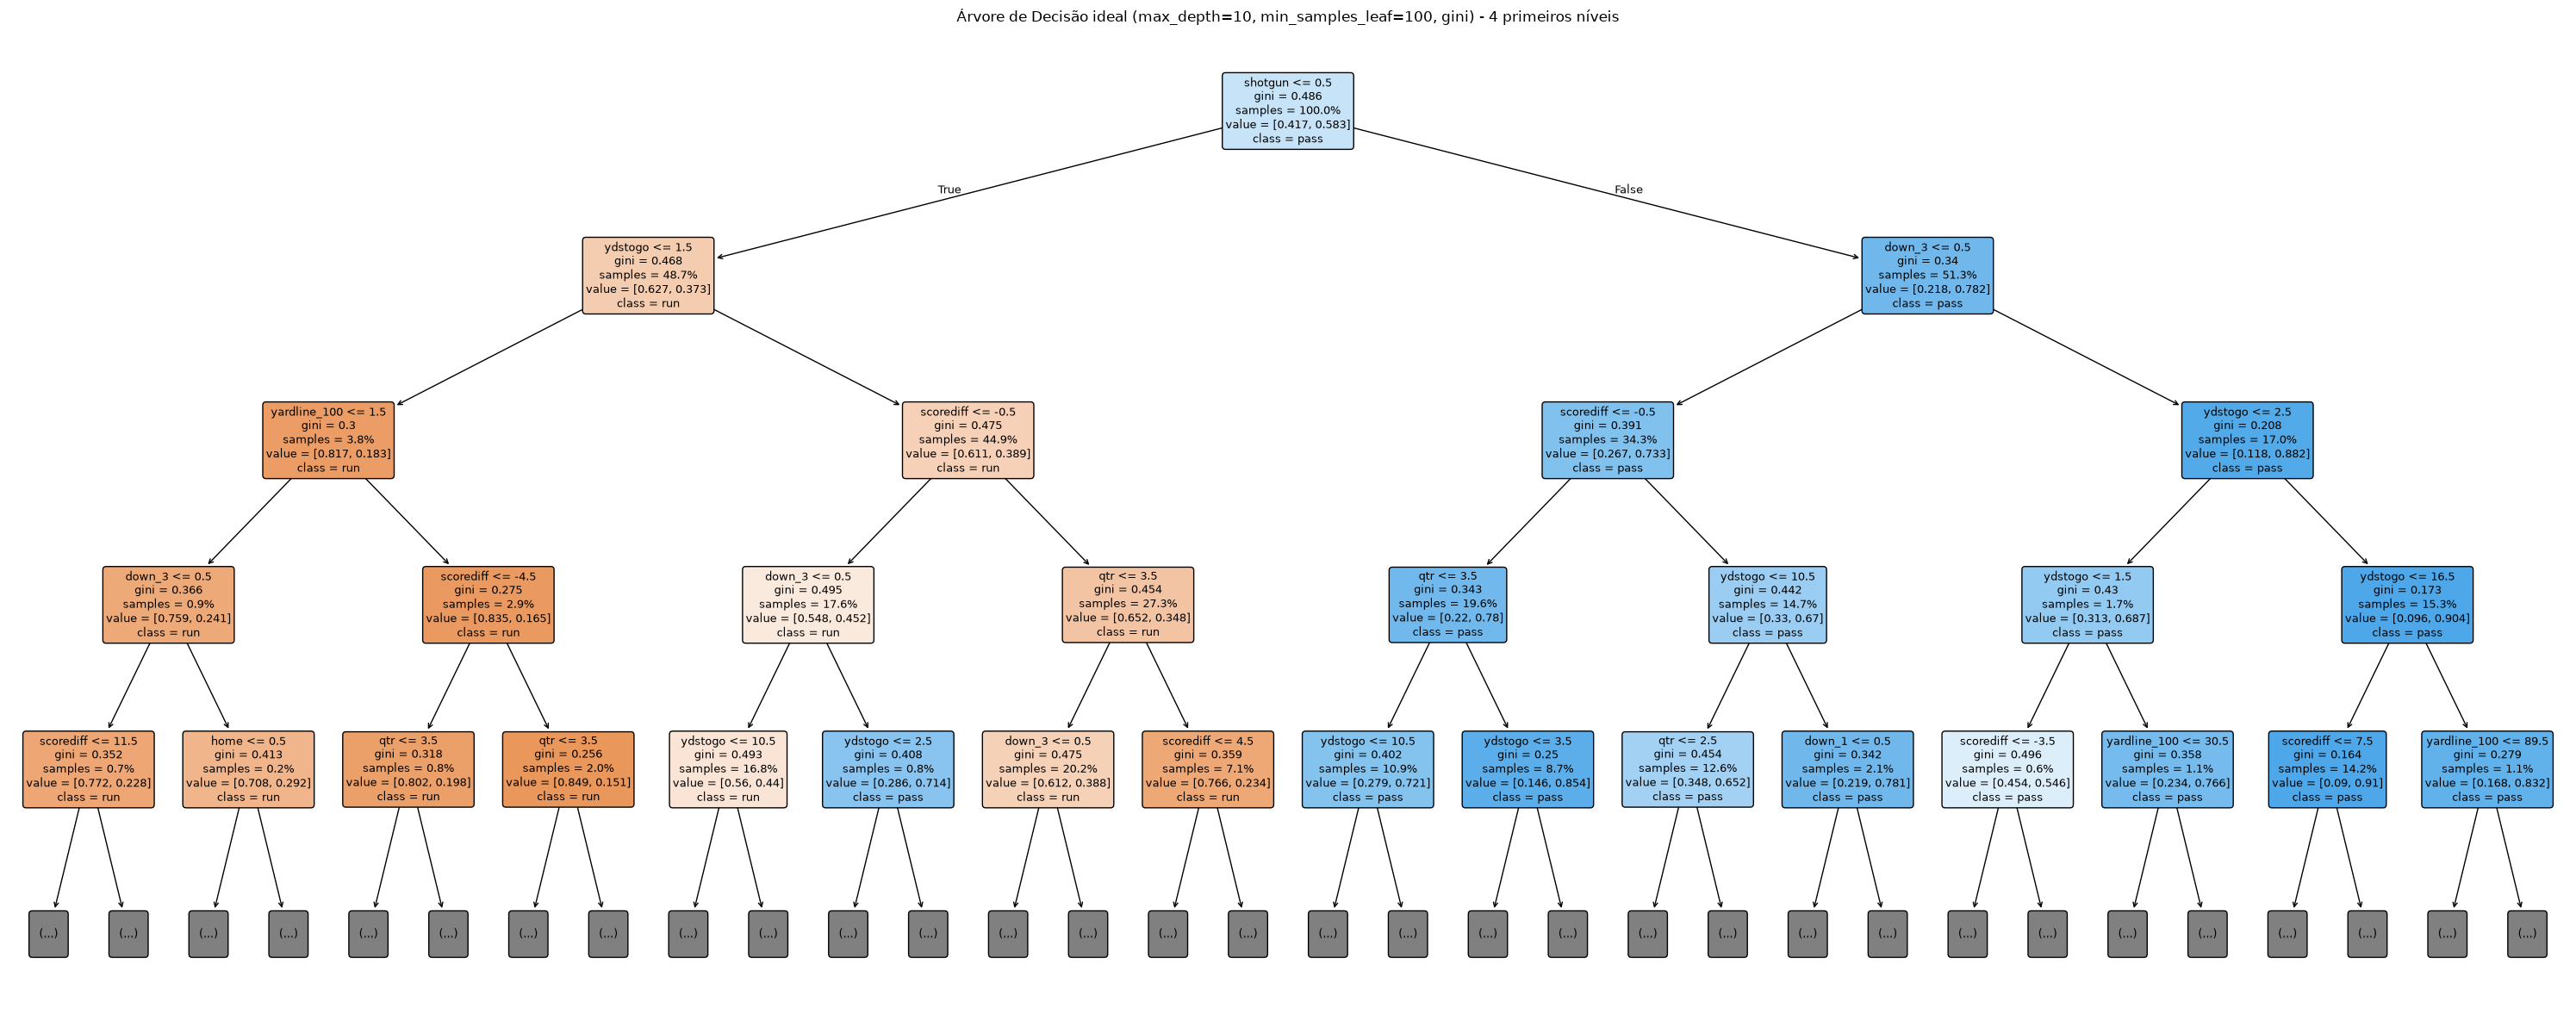

In [11]:
# ===== Árvore ideal (melhor modelo do GridSearchCV) =====
# A árvore ideal tem max_depth=10 e min_samples_leaf=100, ou seja, é grande demais
# para caber legível em uma imagem só. Então geramos duas versões:
#   1) PNG com os 4 primeiros níveis (leitura fácil, bom para relatório/slide)
#   2) PDF vetorial com a árvore COMPLETA (dá para dar zoom sem perder qualidade)
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

print("Hiperparâmetros:", gs.best_params_)
print("Profundidade real:", best.get_depth(), "| Folhas:", best.get_n_leaves(),
      "| Nós totais:", best.tree_.node_count)

# --- 1) Versão resumida (topo da árvore) ---
plt.figure(figsize=(30, 12))
plot_tree(
    best,
    feature_names=FEATURES,
    class_names=["run", "pass"],
    filled=True,
    rounded=True,
    fontsize=9,
    proportion=True,
    max_depth=4,          # só desenha os 4 primeiros níveis; o modelo em si não muda
)
plt.title("Árvore de Decisão ideal (max_depth=10, min_samples_leaf=100, gini) - 4 primeiros níveis")
plt.tight_layout()
plt.savefig("arvore_ideal_topo.png", dpi=300, bbox_inches="tight")
plt.show()

# --- 2) Versão completa em PDF vetorial ---
fig = plt.figure(figsize=(120, 40))
plot_tree(
    best,
    feature_names=FEATURES,
    class_names=["run", "pass"],
    filled=True,
    rounded=True,
    fontsize=6,
    proportion=True,
)
fig.savefig("arvore_ideal_completa.pdf", bbox_inches="tight")
plt.close(fig)

In [7]:
# ===== Random Forest: baseline =====
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,        # número de árvores
    max_depth=None,          # deixa crescer; o min_samples_leaf já controla o overfitting
    min_samples_leaf=50,
    max_features="sqrt",     # cada split olha ~sqrt(13) ≈ 3 features sorteadas
    n_jobs=-1,
    random_state=42,
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print("Acurácia RF:", accuracy_score(y_test, y_pred_rf))
print("Precision (run):", precision_score(y_test, y_pred_rf, pos_label=0))
print("Recall    (run):", recall_score(y_test, y_pred_rf, pos_label=0))
print(classification_report(y_test, y_pred_rf, target_names=["run", "pass"]))

# Comparação com os modelos anteriores (teste 2018)
print("\n--- Comparação (acurácia no teste 2018) ---")
print("Árvore max_depth=5     :", accuracy_score(y_test, y_pred))
print("Árvore ideal (grid)    :", accuracy_score(y_test, y_pred_best))
print("Random Forest baseline :", accuracy_score(y_test, y_pred_rf))

Acurácia RF: 0.7211864406779661
Precision (run): 0.6861155063291139
Recall    (run): 0.5786971390441238
              precision    recall  f1-score   support

         run       0.69      0.58      0.63     11989
        pass       0.74      0.82      0.78     17511

    accuracy                           0.72     29500
   macro avg       0.71      0.70      0.70     29500
weighted avg       0.72      0.72      0.72     29500


--- Comparação (acurácia no teste 2018) ---
Árvore max_depth=5     : 0.7157627118644068
Árvore ideal (grid)    : 0.7213559322033898
Random Forest baseline : 0.7211864406779661


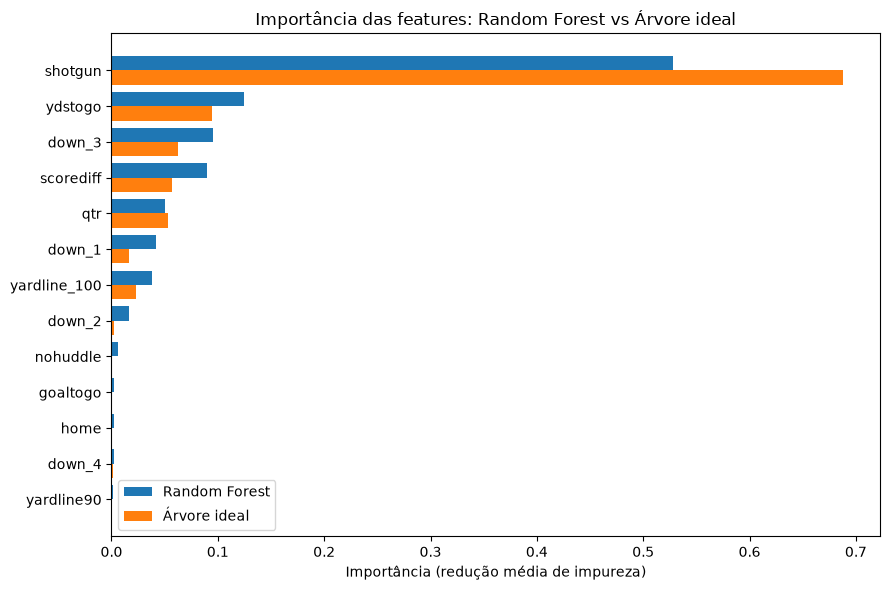

In [8]:
# ===== Random Forest: importância das features =====
import matplotlib.pyplot as plt

imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp_tree = pd.Series(best.feature_importances_, index=FEATURES).reindex(imp.index)

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(imp))
ax.barh(y + 0.2, imp.values, height=0.4, label="Random Forest")
ax.barh(y - 0.2, imp_tree.values, height=0.4, label="Árvore ideal")
ax.set_yticks(y)
ax.set_yticklabels(imp.index)
ax.set_xlabel("Importância (redução média de impureza)")
ax.set_title("Importância das features: Random Forest vs Árvore ideal")
ax.legend()
plt.tight_layout()
plt.savefig("importancia_features_rf.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
# ===== Random Forest: busca de hiperparâmetros =====
# RandomizedSearchCV em vez de GridSearchCV: com ~289k linhas e 200+ árvores por
# candidato, o grid completo ficaria muito lento. Mantém o GroupKFold por temporada.
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [20, 50, 100],
    "max_features": ["sqrt", "log2", 0.5],
}

rs = RandomizedSearchCV(
    estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
    param_distributions=param_dist,
    n_iter=12,
    cv=GroupKFold(n_splits=5),
    scoring="accuracy",
    random_state=42,
    verbose=2,
)

rs.fit(X_train, y_train, groups=train["season"])

print("Melhores parâmetros RF:", rs.best_params_)
print("Melhor acurácia (CV):", rs.best_score_)

best_rf = rs.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)
print("Acurácia RF ajustada (teste 2018):", accuracy_score(y_test, y_pred_best_rf))
print(classification_report(y_test, y_pred_best_rf, target_names=["run", "pass"]))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END max_depth=20, max_features=0.5, min_samples_leaf=50, n_estimators=300; total time=  10.9s
[CV] END max_depth=20, max_features=0.5, min_samples_leaf=50, n_estimators=300; total time=  10.2s
[CV] END max_depth=20, max_features=0.5, min_samples_leaf=50, n_estimators=300; total time=  12.5s
[CV] END max_depth=20, max_features=0.5, min_samples_leaf=50, n_estimators=300; total time=  13.2s
[CV] END max_depth=20, max_features=0.5, min_samples_leaf=50, n_estimators=300; total time=  12.3s
[CV] END max_depth=10, max_features=log2, min_samples_leaf=20, n_estimators=200; total time=   4.9s
[CV] END max_depth=10, max_features=log2, min_samples_leaf=20, n_estimators=200; total time=   5.2s
[CV] END max_depth=10, max_features=log2, min_samples_leaf=20, n_estimators=200; total time=   4.7s
[CV] END max_depth=10, max_features=log2, min_samples_leaf=20, n_estimators=200; total time=   4.5s
[CV] END max_depth=10, max_features=log2, mi